# Sistema de recomendación basado en contenido sobre BindingDB

**Datos Masivos II — práctica de sistemas de recomendación**


***Equipo. 4***

***Integrantes: Cruz Mendoza Valentina Ayelen, Monroy Villegas Isaac, Martinez Perez Ángel Noel***


La traducción que hicimos es esta:

| Concepto del recomendador | Aquí |
|---|---|
| Usuario (el que recibe la recomendación) | **Proteína objetivo** (la diana farmacológica) |
| Ítem (lo que se recomienda) | **Ligando** (la molécula pequeña, el fármaco candidato) |
| Rating (la calificación) | **IC50**, convertido a pIC50 |
| Atributos del ítem | La **estructura del ligando**, su SMILES |
| Matriz de calificaciones | Matriz proteína × ligando, casi toda vacía |

O sea: queremos poder llegar con una proteína y que el sistema nos conteste *"de todas estas moléculas que nunca te han probado, estas 10 son las que probablemente se te peguen más fuerte"*. Es exactamente el problema de llenar los huecos de la matriz de ratings, nomás que los candidatos son fármacos.

### ¿Por qué el IC50 funciona como rating?

El IC50 es la concentración de ligando que hace falta para inhibir a la mitad la actividad de la proteína. Entre **menos** concentración necesites, **mejor** se pegan, así que es un rating al revés: 1 nM es excelente y 100000 nM es malísimo. Por eso lo volteamos con la transformación que se usa en quimioinformática:

$$\text{pIC50} = -\log_{10}(\text{IC50 en molar}) = 9 - \log_{10}(\text{IC50 en nM})$$

Así queda como cualquier calificación normal: **más alto = mejor afinidad**, y además en una escala bonita (más o menos de 2 a 12, con la mayoría entre 5 y 9) en lugar de los brincos de órdenes de magnitud del IC50 crudo.

### Los 3 componentes

Un recomendador basado en contenido se arma con tres componentes, y así organizamos el notebook:

1. **Preprocesamiento y extracción de características** (offline) — convertir el SMILES de cada molécula en un vector TF-IDF.
2. **Aprendizaje del perfil del usuario** (offline) — un modelo por proteína, entrenado *sólo* con las moléculas que esa proteína ya tiene medidas.
3. **Filtrado y recomendación** (online) — rankear los candidatos y devolver el Top-k.

Y al final evaluamos las dos formas de ver el problema: **predicción** (adivinar el pIC50 exacto, lo medimos con RMSE) y **ranking / Top-k** (nomás ordenar bien, lo medimos con precision@k).

## 0. Preparativos



In [1]:
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.naive_bayes import BernoulliNB
from sklearn.feature_selection import chi2
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics import root_mean_squared_error, roc_auc_score
from scipy.sparse.csgraph import connected_components

TSV = Path("BindingDB_All.tsv")          # el dataset tal cual lo bajamos (~9 GB)
CACHE = Path("ic50_cache.parquet")       # para no releer los 9 GB cada vez
CACHE_GRUPOS = Path("grupos_cache.npz")  # los grupos del split 

N_TARGETS = 10        # cuantas proteinas nos llevamos (las que mas datos tienen)
UMBRAL_ACTIVO = 7.0   # pIC50 >= 7  <=>  IC50 <= 100 nM  ->  le llamamos "activo"
K_VECINOS = 25        # k del kNN
SIM_GEMELAS = 0.90    # arriba de esta similitud consideramos dos moleculas "la misma idea"
SEMILLA = 42

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
np.random.seed(SEMILLA)

## 1. Cargar los datos 

El archivo `BindingDB_All.tsv` pesa como **9 GB** y trae **640 columnas**. Si le hacemos un `pd.read_csv` normal nos quedamos sin RAM, entonces hicimos tres cosas:

1. Pedimos **nada más 4 columnas** (`usecols`): el SMILES del ligando, el nombre de la proteína, el organismo y el IC50.
2. Lo leímos **por trozos** (`chunksize`) y en cada trozo tiramos de una vez las filas sin IC50, que son la mayoría (el dataset también trae Ki, Kd, EC50...).
3. Guardamos el resultado en un **parquet** para que la segunda corrida sea instantánea.

Un detalle: el archivo trae SMILES con comillas por ahí, así que le pusimos `quoting=csv.QUOTE_NONE` y `on_bad_lines="skip"` para que no se nos descarrile el parser.

In [2]:
COLS = [1, 6, 7, 9]  # Ligand SMILES | Target Name | Target Source Organism | IC50 (nM)
NOMBRES = ["smiles", "target", "organismo", "ic50_txt"]

if CACHE.exists():
    crudo = pd.read_parquet(CACHE)
    print("leido del cache")
else:
    trozos = []
    for i, ch in enumerate(pd.read_csv(TSV, sep="\t", usecols=COLS, dtype=str,
                                       chunksize=500_000, quoting=csv.QUOTE_NONE,
                                       on_bad_lines="skip")):
        ch.columns = NOMBRES
        trozos.append(ch.dropna(subset=["ic50_txt"]))
        print(f"  trozo {i}: {len(trozos[-1]):>7,} filas con IC50", end="\r")
    crudo = pd.concat(trozos, ignore_index=True)
    del trozos
    crudo.to_parquet(CACHE, compression="gzip", index=False)
    print("\nleido del TSV y guardado en cache")

print(f"\nfilas con IC50: {len(crudo):,}")
crudo.head(3)

leido del cache

filas con IC50: 2,220,490


,smiles,target,organismo,ic50_txt
0,Cc1nc(CN2CCN(c3c(Cl)cnc4[nH]c(-c5cn(C)nc5C)nc34)CC2)no1,Cytochrome P450 3A4,Homo sapiens,>50000
1,O=C1CCCC2=C1C1(CCS(=O)(=O)C1)N=C(Nc1nc3ccccc3o1)N2,Galactokinase,Homo sapiens,6676.9
2,CC(C)[C@H](NC(C)=O)C(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CN(CC...,Dimer of Gag-Pol polyprotein [489-587],Human immunodeficiency virus 1,8.5


## 2. Limpieza

Aquí es donde se decide si el "rating" sirve o no. Lo que hicimos:

**a) Nos quedamos sólo con proteínas humanas.** El dataset trae mediciones en rata, ratón, virus, etc. Además hay dos etiquetas (`Homo sapiens` y `Human`) que son lo mismo.

**b) Tiramos los valores censurados.** Un buen pedazo de los IC50 vienen como `>10000` o `<0.5`. Eso significa *"se nos salió del rango del experimento"*, no es un número. Imputarlos sería inventar ratings, así que los quitamos 


**c) pIC50 y recortess.** Convertimos a pIC50 y nos quedamos en un rango físicamente creíble (2 a 12). Lo que sale de ahí son casi siempre errores de captura.

In [3]:
HUMANO = {"Homo sapiens", "Human"}

d = crudo[crudo["organismo"].isin(HUMANO)].copy()
print(f"solo humano:            {len(d):>10,}")

censurado = d["ic50_txt"].str.contains(r"[<>]", na=False)
print(f"censurados (> o <):     {censurado.sum():>10,}  ({censurado.mean():.1%}) -> fuera")
d = d[~censurado]

d["ic50"] = pd.to_numeric(d["ic50_txt"].str.strip(), errors="coerce")
d = d.dropna(subset=["ic50", "smiles", "target"])
d = d[d["ic50"] > 0]
print(f"numericos y positivos:  {len(d):>10,}")

d["pic50"] = 9 - np.log10(d["ic50"])
d = d[d["pic50"].between(2, 12)]
print(f"pIC50 en [2, 12]:       {len(d):>10,}")

d = d[["target", "smiles", "ic50", "pic50"]].reset_index(drop=True)
d["pic50"].describe()

solo humano:             1,885,910
censurados (> o <):        417,909  (22.2%) -> fuera
numericos y positivos:   1,467,870
pIC50 en [2, 12]:        1,466,789


count    1.466789e+06
mean     6.803984e+00
std      1.383503e+00
min      2.000000e+00
25%      5.796614e+00
50%      6.853872e+00
75%      7.795880e+00
max      1.200000e+01
Name: pic50, dtype: float64

### El mismo par medido varias veces

Otra cosa que nos encontramos: el mismo par proteína–ligando aparece repetido porque lo midieron en papers distintos, y no siempre coinciden.
Lo resolvimos con la **mediana** por par (más robusta que el promedio ante un outlier), y revisamos qué tanto se contradicen entre ellos.

In [4]:
agg = d.groupby(["target", "smiles"])["pic50"].agg(["median", "count", "std"])
pares = agg.reset_index().rename(columns={"median": "pic50"})

rep = agg[agg["count"] > 1]
print(f"pares unicos:            {len(pares):,}")
print(f"ligandos unicos:         {pares['smiles'].nunique():,}")
print(f"proteinas unicas:        {pares['target'].nunique():,}")
print(f"pares medidos >1 vez:    {len(rep):,}  ({len(rep)/len(pares):.1%})")
print(f"desacuerdo tipico (std): {rep['std'].median():.2f} unidades de pIC50")

pares = pares[["target", "smiles", "pic50", "count"]]
pares.head()

pares unicos:            1,144,151
ligandos unicos:         788,114
proteinas unicas:        4,011
pares medidos >1 vez:    200,627  (17.5%)
desacuerdo tipico (std): 0.03 unidades de pIC50


,target,smiles,pic50,count
0,"1,25-dihydroxyvitamin D(3) 24-hydroxylase, mitochondrial",Brc1ccc(cc1)C(=O)NCC(c1ccccc1)n1ccnc1,4.638272,1
1,"1,25-dihydroxyvitamin D(3) 24-hydroxylase, mitochondrial",C(CCn1ccc2c(\C=C\c3ccccc3)cccc12)Cn1ccnc1,6.698970,1
2,"1,25-dihydroxyvitamin D(3) 24-hydroxylase, mitochondrial",C(CCn1ccc2cc(\C=C\c3ccccc3)ccc12)Cn1ccnc1,6.283997,1
3,"1,25-dihydroxyvitamin D(3) 24-hydroxylase, mitochondrial",C(Cn1ccnc1)Cn1ccc2c(\C=C\c3ccccc3)cccc12,6.443697,1
4,"1,25-dihydroxyvitamin D(3) 24-hydroxylase, mitochondrial",C(Cn1ccnc1)Cn1ccc2cc(\C=C\c3ccccc3)ccc12,6.283997,1


In [5]:
# el desacuerdo entre mediciones repetidas, con mas detalle
print(rep["std"].describe(percentiles=[.5, .75, .9, .99]).round(2))
print(f"\npares repetidos que coinciden casi exacto (std < 0.05): {(rep['std'] < 0.05).mean():.1%}")

count    200627.00
mean          0.30
std           0.48
min           0.00
50%           0.03
75%           0.44
90%           0.95
99%           2.12
max           4.24
Name: std, dtype: float64

pares repetidos que coinciden casi exacto (std < 0.05): 51.6%


Aquí nos llevamos una sorpresa que vale la pena contar, porque al principio leímos mal el número.

La mediana del desacuerdo sale **0.03**, que es casi cero, y nuestra primera reacción fue *"órale, los datos están limpísimos"*. Pero viendo la distribución completa: **más de la mitad de los pares repetidos coinciden casi exacto** (std < 0.05). Eso no es que los laboratorios del mundo sean increíblemente consistentes — es que muchos de esos "repetidos" son **la misma medición capturada dos veces** en BindingDB (el mismo dato citado en dos papers, o entrando por dos fuentes de curación). No son réplicas independientes.

Y la otra mitad sí se contradice en serio: el percentil 90 anda en **~0.95 unidades de pIC50**, o sea casi **un orden de magnitud de diferencia en IC50** para el mismo par proteína–ligando. Es el *"a mí me gustó 5 y a ti 1"* pero sobre un experimento que supuestamente es objetivo.

Entonces la lección es: la mediana de 0.03 **no** nos sirve como piso de ruido (está contaminada por duplicados). El piso real está más cerca de las décimas de unidad, y es contra eso que hay que juzgar el RMSE del modelo más adelante.

## 3. La matriz de calificaciones

Nos quedamos con las 10 proteínas que más mediciones tienen (son las que tienen suficiente historial para aprenderles un perfil).

In [6]:
conteo = pares["target"].value_counts()
top = conteo.head(N_TARGETS).index
sub = pares[pares["target"].isin(top)].copy()

ligandos = pd.Index(sub["smiles"].unique())
n_t, n_l = len(top), len(ligandos)
densidad = len(sub) / (n_t * n_l)

print(f"proteinas:  {n_t}")
print(f"ligandos:   {n_l:,}")
print(f"celdas:     {n_t * n_l:,}")
print(f"llenas:     {len(sub):,}  ->  densidad {densidad:.2%}  (vacio: {1-densidad:.2%})")
print()

resumen = (sub.groupby("target")
             .agg(mediciones=("pic50", "size"),
                  pic50_medio=("pic50", "mean"),
                  activos=("pic50", lambda s: (s >= UMBRAL_ACTIVO).mean()))
             .sort_values("mediciones", ascending=False))
resumen.style.format({"pic50_medio": "{:.2f}", "activos": "{:.1%}"})

proteinas:  10
ligandos:   89,814
celdas:     898,140
llenas:     92,541  ->  densidad 10.30%  (vacio: 89.70%)



,mediciones,pic50_medio,activos
target,,,
Epidermal growth factor receptor,10935,6.89,49.6%
Tyrosine-protein kinase JAK2,10421,7.08,53.7%
Tyrosine-protein kinase BTK,10022,7.58,70.5%
Potassium voltage-gated channel subfamily H member 2,9060,5.43,6.3%
Sodium channel protein type 9 subunit alpha,8879,6.61,36.5%
"Phosphatidylinositol 4,5-bisphosphate 3-kinase catalytic subunit alpha isoform",8846,6.36,30.9%
Interleukin-1 receptor-associated kinase 4,8772,7.64,70.4%
Vascular endothelial growth factor receptor 2,8656,6.82,44.9%
Histone deacetylase 1,8523,6.64,37.9%


**La matriz queda ~90% vacía** (y eso ya es el caso bonito: nos quedamos con las 10 proteínas más medidas y sólo con los ligandos que alguna de ellas tocó. Si la armáramos con las 4,011 proteínas y los 788 mil ligandos del dataset completo, la densidad se iría a menos del 0.05%).

Y no está vacía por flojera: cada celda llena costó un experimento de laboratorio con dinero y tiempo real. Por eso un recomendador aquí tiene un valor muy concreto — cada hueco que podamos predecir bien es un experimento que no hay que hacer a ciegas.



In [7]:
# un pedazo de la matriz
muestra = sub[sub["smiles"].isin(sub["smiles"].value_counts().head(8).index)]
pivote = muestra.pivot_table(index="smiles", columns="target", values="pic50")
pivote.columns = [c[:22] + "..." if len(c) > 22 else c for c in pivote.columns]
pivote.index = [s[:40] + "..." for s in pivote.index]
pivote.round(2)

,Epidermal growth facto...,Interleukin-1 receptor...,Phosphatidylinositol 4...,Potassium voltage-gate...,Tyrosine-protein kinas...,Tyrosine-protein kinas...,Vascular endothelial g...
C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(C)CC4...,8.75,NaN,NaN,6.00,9.24,6.24,NaN
CC(C)n1c(C)nc2c(F)cc(cc12)-c1nc(Nc2ccc3C...,5.71,NaN,NaN,5.00,NaN,6.77,5.41
CC1(C)C(=O)N([C@H]2CCc3c2cccc3O)c2nc(Nc3...,5.00,5.00,NaN,NaN,5.73,5.93,5.84
CCn1nc(C#Cc2cc(ccc2C)C(=O)Nc2ccc(CN3CCN(...,5.45,NaN,NaN,NaN,7.17,5.54,7.77
CN1CCN(CC1)C2CCN(CC2)c3ccc(c(c3)OC)Nc4nc...,7.55,NaN,NaN,NaN,6.17,6.81,6.09
C[C@@]12[C@@H]([C@@H](C[C@@H](O1)n3c4ccc...,7.21,8.21,NaN,4.04,7.66,8.89,7.96
Cn1cc(cn1)-c1cnc2c(cnn2c1)-c1csc(c1)C(=O...,4.55,7.19,NaN,NaN,6.44,5.92,7.82
Nc1ncnc2c1c(-c1cccc(O)c1)cn2[C@H]1C[C@@H...,5.64,NaN,5.85,6.38,6.24,5.96,6.36


Aun escogiendo los 8 ligandos **más probados de todos**, la tabla sigue llena de huecos. Eso es exactamente lo que vamos a predecir.

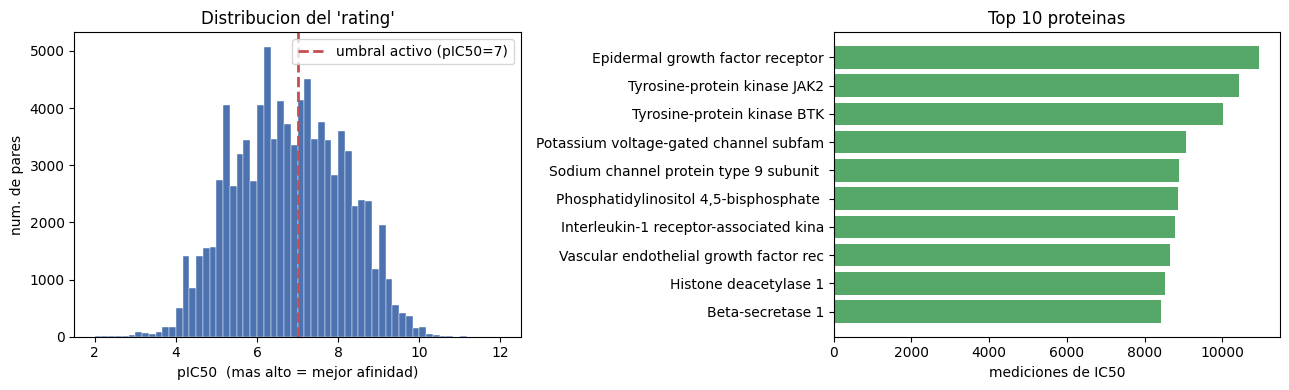

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].hist(sub["pic50"], bins=60, color="#4C72B0", edgecolor="white", linewidth=.3)
ax[0].axvline(UMBRAL_ACTIVO, color="#C44E52", ls="--", lw=2,
              label=f"umbral activo (pIC50={UMBRAL_ACTIVO:g})")
ax[0].set_xlabel("pIC50  (mas alto = mejor afinidad)")
ax[0].set_ylabel("num. de pares")
ax[0].set_title("Distribucion del 'rating'")
ax[0].legend()

r = resumen.sort_values("mediciones")
ax[1].barh([t[:38] for t in r.index], r["mediciones"], color="#55A868")
ax[1].set_xlabel("mediciones de IC50")
ax[1].set_title(f"Top {N_TARGETS} proteinas")

plt.tight_layout()
plt.show()

El histograma sale con una campana centrada como en 6.5–7 y una cola a la derecha. Ojo con una cosa que nos pareció importante: **esto no es una muestra aleatoria de la química**. Nadie publica las moléculas que no hicieron nada; los químicos ya habían optimizado estas series antes de medirlas.

## 4. Componente 1: extracción de características

El contenido de cada ligando es su **SMILES**, que es la estructura de la molécula escrita como cadena de texto:

```
CC(=O)Oc1ccccc1C(=O)O        <- aspirina
```

Lo bonito es que podemos tratarlo **literalmente como texto** y armarle una bolsa de palabras. Pero hay un problema: en un texto normal las palabras vienen separadas por espacios, y en un SMILES no hay espacios. Entonces en lugar de partir por palabras partimos en **n-gramas de caracteres**:

```
c1ccccc1  ->  "c1c", "1cc", "ccc", "cc1", "c1cc", "1ccc", ...
```

Cada n-grama es nuestra "palabra". `c1ccccc1` (un anillo de benceno) va a generar n-gramas que cualquier molécula con benceno también genera — o sea, los n-gramas compartidos son fragmentos estructurales compartidos.

le aplicamos **TF-IDF**:

- **TF con amortiguamiento** (`sublinear_tf=True`, que es el $f(x) = \log(x)$ ): si una molécula es una cadena larguísima de carbonos, el n-grama `CCC` le aparece 40 veces. Sin amortiguar, esa molécula sería "sobre todo CCC" y nada más. 
- **IDF**: los n-gramas que están en *todas* las moléculas (`C`, `c1`, `(=O)`...) no distinguen nada. 
- **`min_df=5`**: si un n-grama sale en menos de 5 moléculas, es ruido. Es nuestro recorte de vocabulario.


In [9]:
# los guardamos en un dict porque mas adelante vamos a reajustar el vectorizador
# SOLO con los datos de entrenamiento, y tiene que ser con los mismos parametros
PARAMS_TFIDF = dict(
    analyzer="char",       # n-gramas de caracteres, no de palabras
    ngram_range=(2, 4),    # pedacitos de 2 a 4 caracteres
    min_df=5,              # n-gramas en <5 moleculas = ruido
    sublinear_tf=True,     # el log(x), para que no domine lo repetido
    lowercase=False,       # ojo: en SMILES 'C' y 'c' son cosas distintas!
)

vec = TfidfVectorizer(**PARAMS_TFIDF)
X = vec.fit_transform(ligandos)
fila = {s: i for i, s in enumerate(ligandos)}   # smiles -> renglon de X

print(f"matriz de features: {X.shape[0]:,} ligandos x {X.shape[1]:,} n-gramas")
print(f"densidad: {X.nnz / (X.shape[0]*X.shape[1]):.3%}  (ralita, por eso es sparse)")
print(f"memoria:  {(X.data.nbytes + X.indices.nbytes + X.indptr.nbytes)/1e6:.0f} MB")

matriz de features: 89,814 ligandos x 14,207 n-gramas
densidad: 1.005%  (ralita, por eso es sparse)
memoria:  154 MB


In [10]:
# a que se parece el vector de la aspirina
aspirina = "CC(=O)Oc1ccccc1C(=O)O"
v = vec.transform([aspirina]).toarray().ravel()
voc = np.array(vec.get_feature_names_out())
orden = v.argsort()[::-1][:12]
pd.DataFrame({"n-grama": voc[orden], "peso tf-idf": v[orden].round(3)})

,n-grama,peso tf-idf
0,=O)O,0.368
1,O)O,0.360
2,O)Oc,0.342
3,)O,0.266
4,)Oc1,0.241
5,)Oc,0.228
6,1C(=,0.196
7,c1C(,0.194
8,1C(,0.176
9,cc1C,0.161


## 5. Partir train / test sin hacernos trampa

Antes de entrenar nada hay que decidir cómo partimos los datos

### Por qué un split aleatorio no sirve

Lo normal sería `train_test_split` y ya: 80% de las moléculas de cada proteína para entrenar, 20% para evaluar. El problema es cómo se publican estos datos. Un paper de química medicinal no reporta una molécula: reporta una **serie** de 30 o 40 análogos de la misma estructura, cambiándole un grupito cada vez. En el dataset eso aparece como 40 moléculas distintas que son casi la misma.

Si partimos al azar, esas 40 se reparten entre train y test. Entonces cuando evaluamos, el modelo ya vio prácticamente la misma molécula durante el entrenamiento, y nuestro kNN nomás tiene que acordarse en lugar de generalizar. Eso es una **fuga de datos**: el número que reportamos sale bonito pero no mide lo que dice medir.

Y hay un caso todavía más descarado: el mismo compuesto se puede escribir de varias formas válidas en SMILES. Como nosotros agrupamos por la cadena de texto, la misma molécula escrita de dos maneras cuenta como dos moléculas distintas — y se puede ir una a train y otra a test. Ahí el modelo literalmente tiene la respuesta.

### Cómo lo arreglamos

La idea es sencilla: **si dos moléculas se parecen demasiado, tienen que caer las dos del mismo lado.** Así que en lugar de partir moléculas sueltas, partimos **grupos de moléculas parecidas**:

1. Para cada molécula buscamos sus 20 vecinas más cercanas por coseno.
2. Nos quedamos nomás con las conexiones de similitud > 0.90, y armamos un grafo.
3. Sacamos las **componentes conexas** de ese grafo: cada componente es un bloque de moléculas encadenadas por parecido, o sea más o menos una serie química.
4. Partimos con `GroupShuffleSplit` usando esas componentes como grupos, así que ninguna componente queda partida.

Lo bueno de las componentes conexas es que la garantía es **estructural**, no estadística: si A y B quedaron conectadas, acaban en la misma componente, y si están en la misma componente caen forzosamente del mismo lado. El único hueco es el paso 1, porque sólo miramos 20 vecinas por molécula: si una molécula tuviera más de 20 gemelas, la número 21 podría quedarse sin arista. Más abajo medimos cuánto se cuela por ese hueco (adelanto: casi nada).

Probamos también agrupar con k-means y quedaba fuga residual (los clusters tienen frontera y las gemelas de la orilla se separaban), así que nos quedamos con las componentes. Lo del grafo tarda unos minutos, por eso lo guardamos en caché.

In [11]:
if CACHE_GRUPOS.exists():
    grupo_de = pd.Series(np.load(CACHE_GRUPOS)["grupo"], index=ligandos)
    print("grupos leidos del cache")
else:
    # 1-2) grafo de vecinos, nos quedamos solo con las aristas muy parecidas
    print("armando el grafo de vecinos (tarda unos minutos)...")
    G = kneighbors_graph(X, n_neighbors=20, metric="cosine", mode="distance", n_jobs=-1)
    G.data = (G.data < (1 - SIM_GEMELAS)).astype(np.int8)
    G.eliminate_zeros()

    # 3) componentes conexas = bloques de moleculas encadenadas por parecido
    n_grupos, etiquetas = connected_components(G, directed=False)
    grupo_de = pd.Series(etiquetas, index=ligandos)
    np.savez_compressed(CACHE_GRUPOS, grupo=etiquetas)
    print(f"listo: {n_grupos:,} grupos")

sub["grupo"] = sub["smiles"].map(grupo_de)

tam = grupo_de.value_counts()
print(f"\ngrupos:              {len(tam):,}")
print(f"grupos de 1 molecula:  {(tam == 1).sum():,}  ({(tam == 1).mean():.1%})")
print(f"grupo mas grande:      {tam.max():,} moleculas ({tam.max()/len(ligandos):.1%} del catalogo)")
print(f"tamano mediano:        {tam.median():.0f}")

grupos leidos del cache

grupos:              40,434
grupos de 1 molecula:  27,381  (67.7%)
grupo mas grande:      366 moleculas (0.4% del catalogo)
tamano mediano:        1


In [12]:
# 4) un split por grupos para cada proteina
splits = {}
for nombre in resumen.index:
    dt = sub[sub["target"] == nombre]
    gss = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEMILLA)
    i_tr, i_te = next(gss.split(np.arange(len(dt)), groups=dt["grupo"].to_numpy()))
    splits[nombre] = (i_tr, i_te)

pd.DataFrame([{"proteina": n[:34], "train": len(a), "test": len(b),
               "%test": len(b)/(len(a)+len(b))}
              for n, (a, b) in splits.items()]).style.format({"%test": "{:.1%}"})

,proteina,train,test,%test
0,Epidermal growth factor receptor,9001,1934,17.7%
1,Tyrosine-protein kinase JAK2,8187,2234,21.4%
2,Tyrosine-protein kinase BTK,8173,1849,18.4%
3,Potassium voltage-gated channel su,7319,1741,19.2%
4,Sodium channel protein type 9 subu,6762,2117,23.8%
5,"Phosphatidylinositol 4,5-bisphosph",7031,1815,20.5%
6,Interleukin-1 receptor-associated,6852,1920,21.9%
7,Vascular endothelial growth factor,6852,1804,20.8%
8,Histone deacetylase 1,6858,1665,19.5%
9,Beta-secretase 1,6631,1796,21.3%


### ¿De verdad se fue la fuga?

No lo damos por hecho, lo medimos. Para cada molécula de prueba buscamos su vecina más parecida **dentro del entrenamiento** y vemos qué tan parecida es. Comparamos el split aleatorio contra el nuestro: si el arreglo sirve, las "gemelas" tienen que desaparecer.

In [13]:
def mide_fuga(Xd, i_tr, i_te):
    """Para cada molecula de test, que tan parecida es su vecina mas cercana del train."""
    nn = NearestNeighbors(n_neighbors=1, metric="cosine").fit(Xd[i_tr])
    s = 1 - nn.kneighbors(Xd[i_te])[0].ravel()
    return {"n_test": len(i_te), "sim>0.99": (s > .99).mean(),
            "sim>0.95": (s > .95).mean(), "sim>0.90": (s > .90).mean(), "sim_media": s.mean()}


chequeo = []
for nombre in resumen.index:
    dt = sub[sub["target"] == nombre]
    Xd = X[dt["smiles"].map(fila).to_numpy()]
    n = len(dt)

    # el split aleatorio de toda la vida, nomas para comparar
    rng = np.random.default_rng(SEMILLA)
    perm = rng.permutation(n)
    corte = int(.8 * n)
    chequeo.append({"proteina": nombre[:30], "split": "aleatorio",
                    **mide_fuga(Xd, perm[:corte], perm[corte:])})
    # el nuestro
    i_tr, i_te = splits[nombre]
    chequeo.append({"proteina": nombre[:30], "split": "por grupos",
                    **mide_fuga(Xd, i_tr, i_te)})

chk = pd.DataFrame(chequeo)
print(chk.groupby("split")[["sim>0.99", "sim>0.95", "sim>0.90", "sim_media"]]
         .mean().to_string(float_format=lambda v: f"{v:.3f}"))
print()
chk.set_index(["proteina", "split"]).style.format({
    "sim>0.99": "{:.2%}", "sim>0.95": "{:.2%}", "sim>0.90": "{:.2%}", "sim_media": "{:.3f}"})

            sim>0.99  sim>0.95  sim>0.90  sim_media
split                                              
aleatorio      0.095     0.417     0.650      0.891
por grupos     0.000     0.000     0.001      0.788



Ahí está el tamaño del problema que teníamos encima:

| | sim > 0.99 | sim > 0.95 | sim > 0.90 | similitud media |
|---|---|---|---|---|
| split aleatorio | 9.5% | **41.7%** | 65.0% | 0.891 |
| split por grupos | **0.0%** | **0.0%** | 0.1% | 0.788 |

Tres cosas que leemos de esta tabla:

- **La fuga no era un detalle, era enorme.** Con el split aleatorio, **4 de cada 10 moléculas de prueba tenían una casi gemela** (similitud > 0.95) en el entrenamiento, y casi 1 de cada 10 tenía una copia prácticamente idéntica (> 0.99). Si hubiéramos reportado esos números, estaríamos presumiendo que el modelo generaliza cuando buena parte del mérito era acordarse.
- **El arreglo funciona.** Con el split por grupos no queda **ninguna** molécula de prueba con una gemela arriba de 0.95. En el umbral exacto de 0.90 se cuela un **0.1%**, que es justo el huequito de las 20 vecinas que mencionamos arriba. Nos parece aceptable y preferimos reportarlo que decir "cero" de dientes para afuera.
- **La similitud media también baja** (0.891 → 0.788). No sólo se van las gemelas: el conjunto de prueba completo queda más lejos del entrenamiento. Eso es justo lo que queremos, porque es la situación real — cuando usemos el recomendador de verdad, los candidatos van a ser moléculas de series que esa proteína nunca ha visto.

Así que de aquí para abajo, **todos los números salen del split por grupos**. Van a ser más feos que con el split aleatorio, y eso es precisamente la razón para confiar en ellos.

## 6. Pesar las features


Fíjense en lo que acabamos de hacer: el IDF y el `min_df` decidieron qué pesa más **mirando nada más el catálogo de moléculas**. A ninguna proteína le preguntamos nada. Son métodos **no supervisados**.

Ahora vamos a hacer lo supervisado: que cada proteína nos diga qué fragmentos le importan *a ella*. Con la implementación de dos puntajes:

**χ² (ji cuadrada)** — mira las 4 celdas de la tabla 2×2 *¿tiene el fragmento?* × *¿es activo?* y pregunta si se aleja de la casualidad. Mira **todas** las moléculas, con y sin el fragmento. Mayor χ² = mejor fragmento. Lo sacamos con `sklearn.feature_selection.chi2`.

**Desviación normalizada** — usa el rating **como número y respeta el orden**. Los puntajes de tipo χ² sólo saben de categorías: para ellos un pIC50 de 5 contra uno de 6 es tan distinto como un 5 contra un 9. Esta sí usa la distancia, que es lo que queremos porque nuestro pIC50 es continuo:

$$\text{Dev}(w) = \frac{|\mu^{+}(w) - \mu^{-}(w)|}{\sigma}$$

donde $\mu^{+}$ es el pIC50 promedio de las moléculas **con** el fragmento, $\mu^{-}$ el de las que **no** lo tienen, y $\sigma$ la desviación estándar de todas. Se lee bonito: *"tener este fragmento te mueve el pIC50 tantas desviaciones estándar"*.

Ojo con un detalle: estos puntajes usan las calificaciones, así que los calculamos **nada más con las moléculas de entrenamiento**. Si los sacáramos con todo, estaríamos mirando las respuestas del examen antes de hacerlo — otra forma de la misma fuga.



In [14]:
def dev_normalizada(Xb, y):
    """Dev(w) = |mu+ - mu-| / sigma  para cada feature. Xb binaria (sparse), y continuo."""
    n = Xb.shape[0]
    n_con = np.asarray(Xb.sum(axis=0)).ravel()          # en cuantas moleculas esta el fragmento
    suma_con = np.asarray(Xb.T @ y).ravel()             # suma de pIC50 de esas
    n_sin = n - n_con
    suma_sin = y.sum() - suma_con
    with np.errstate(invalid="ignore", divide="ignore"):
        mu_con = suma_con / n_con
        mu_sin = suma_sin / n_sin
    dev = np.abs(mu_con - mu_sin) / y.std()
    dev[(n_con < 10) | (n_sin < 10)] = np.nan          # sin soporte no opinamos
    return dev, n_con


# lo corremos sobre la proteina con mas datos, SOLO con sus moleculas de entrenamiento
proteina_demo = resumen.index[0]
dd = sub[sub["target"] == proteina_demo].iloc[splits[proteina_demo][0]]
idx = dd["smiles"].map(fila).to_numpy()
Xd = X[idx]
yd = dd["pic50"].to_numpy()
yd_bin = (yd >= UMBRAL_ACTIVO).astype(int)

Xd_bin = (Xd > 0).astype(np.float64)
chi, _ = chi2(Xd_bin, yd_bin)
dev, n_con = dev_normalizada(Xd_bin, yd)

puntajes = pd.DataFrame({
    "n-grama": vec.get_feature_names_out(),
    "en_n_moleculas": n_con.astype(int),
    "chi2": chi,
    "dev_norm": dev,
    "idf": vec.idf_,
}).dropna()

print(f"proteina: {proteina_demo}")
print(f"moleculas con medicion: {len(dd):,}   activas: {yd_bin.mean():.1%}\n")
print("Top 10 fragmentos segun DESVIACION NORMALIZADA (usa el pIC50 como numero):")
puntajes.nlargest(10, "dev_norm").round(2).to_string(index=False)

proteina: Epidermal growth factor receptor
moleculas con medicion: 9,001   activas: 50.1%

Top 10 fragmentos segun DESVIACION NORMALIZADA (usa el pIC50 como numero):


'n-grama  en_n_moleculas  chi2  dev_norm  idf\n   )=Cc              21 21.05      2.37 8.97\n   #N)=              34 30.20      1.91 7.64\n   N)=C              34 30.20      1.91 7.59\n   C2NC              10 10.02      1.87 8.19\n   4c3P              18 17.96      1.85 9.19\n   =Cc1              45 41.19      1.79 7.15\n   3)n[              65 65.16      1.78 7.08\n   2c(/              62 62.15      1.78 7.88\n   C(C#              59 44.21      1.77 6.09\n    1Sc              65 65.16      1.77 7.41'

Top 10 fragmentos segun CHI2 (usa activo/inactivo):
n-grama  en_n_moleculas   chi2  dev_norm  idf
    =CN             653 519.08      1.01 5.70
   =CN(             592 502.24      1.04 5.86
    )NN             720 488.60      0.94 5.53
   ](Nc             606 427.96      0.93 4.95
   C)(C            1038 352.31      0.71 3.41
    )(C            1049 352.07      0.71 3.22
   )(C)            1008 350.94      0.73 3.51
   H](N             692 337.34      0.80 3.74
    ](N             692 337.34      0.80 3.74
   NN3)             406 336.29      1.04 6.30



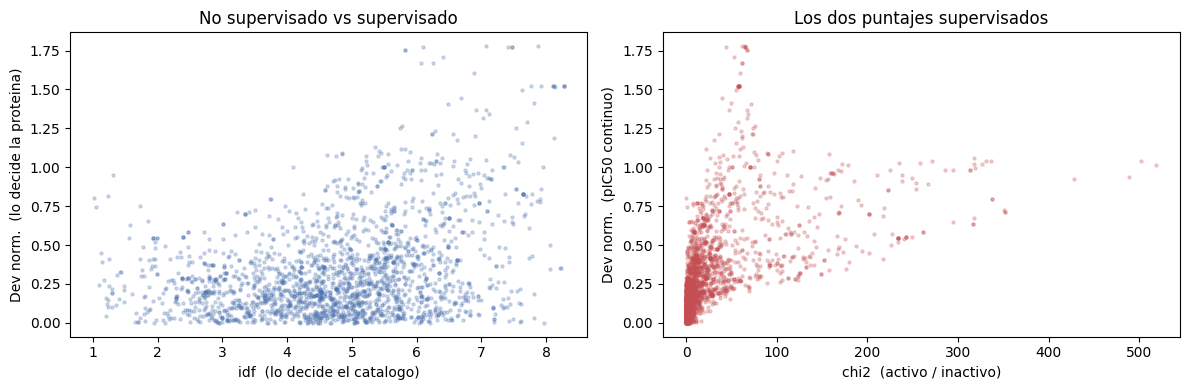

correlacion idf vs dev_norm:  +0.352
correlacion chi2 vs dev_norm: +0.529


In [15]:
print("Top 10 fragmentos segun CHI2 (usa activo/inactivo):")
print(puntajes.nlargest(10, "chi2").round(2).to_string(index=False))
print()

# los dos puntajes supervisados contra el idf, que es el no supervisado
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m = puntajes[puntajes["en_n_moleculas"] > 50]
ax[0].scatter(m["idf"], m["dev_norm"], s=5, alpha=.25, color="#4C72B0")
ax[0].set_xlabel("idf  (lo decide el catalogo)")
ax[0].set_ylabel("Dev norm.  (lo decide la proteina)")
ax[0].set_title("No supervisado vs supervisado")
ax[1].scatter(m["chi2"], m["dev_norm"], s=5, alpha=.25, color="#C44E52")
ax[1].set_xlabel("chi2  (activo / inactivo)")
ax[1].set_ylabel("Dev norm.  (pIC50 continuo)")
ax[1].set_title("Los dos puntajes supervisados")
plt.tight_layout()
plt.show()

print(f"correlacion idf vs dev_norm:  {m['idf'].corr(m['dev_norm']):+.3f}")
print(f"correlacion chi2 vs dev_norm: {m['chi2'].corr(m['dev_norm']):+.3f}")

Aquí la correlación entre IDF y desviación normalizada sale **+0.35**: positiva, pero bajita. O sea **sí se parecen pero no son lo mismo**, y hay un montón de fragmentos donde abiertamente no coinciden. En la nube de puntos de la izquierda se ve que hay fragmentos con IDF altísimo (rarísimos en el catálogo) que a esta proteína le dan exactamente igual, y fragmentos bastante comunes que son los que de verdad separan activo de inactivo.

Entre los dos supervisados la correlación es **+0.53**, también lejos de 1, porque miden cosas distintas: χ² sólo sabe de activo/inactivo y la desviación normalizada sí usa el número. Eso se nota clarísimo en las tablas: χ² escoge fragmentos **comunes** (de 400 a 1050 moléculas), porque con tantos datos detecta desviaciones chiquitas de la casualidad; la desviación normalizada escoge fragmentos **raros pero drásticos** (de 10 a 65 moléculas).

Como nuestro rating es continuo, nos quedamos con la desviación normalizada para el experimento de ponderación.

### ¿Y ponderar sirve de algo?

$\text{peso}(w) = \text{idf}(w) \times g(w)$. Lo probamos de verdad más abajo, dentro de la evaluación, en lugar de nomás contarlo 

## 7. Componente 2: aprender el perfil de cada proteína

Lo más importante de este bloque, y lo que lo hace "basado en contenido" y no colaborativo: **un modelo por proteína, entrenado sólo con los datos de esa proteína.** Las otras 9 no participan.

Entrenamos tres cosas por proteína:

**1. kNN con coseno (perezoso).** Para predecirle el pIC50 a una molécula nueva: buscamos sus $k$ moléculas más parecidas entre las que la proteína ya tiene medidas, y promediamos sus pIC50 pesando por la similitud.

$$\cos(X, Y) = \frac{\sum_i x_i y_i}{\sqrt{\sum_i x_i^2}\sqrt{\sum_i y_i^2}}$$

El coseno mide el **ángulo, no el largo** —  no queremos que una molécula grande parezca distinta nomás por grande.

Esto es, un principio que los químicos llaman *similarity property principle*: moléculas parecidas se pegan parecido. 

**2. Naive Bayes Bernoulli (eager).** El kNN es carísimo (cuesta $|D_L| \times |D_U|$ comparaciones y no entrena nada), así que entrenamos un clasificador antes. Usamos **Bernoulli** porque modela *si el fragmento está o no está*, que es justo lo que nos importa (no cuántas veces). La hipótesis naive — que cada fragmento aparece independiente de los demás — es **falsísima** en química (los átomos están conectados, de ahí los n-gramas que se traslapan), pero igual suele funcionar, y eso también es parte de la lección.

**3. La línea base.** Predecir siempre el promedio de la proteína. **Esta es la que hay que ganar.** Si nuestro modelo elegante no le gana a "predice el promedio", no aprendimos nada. Nos pareció importante ponerla porque es muy fácil enamorarse de un RMSE sin saber si es bueno.

In [16]:
def knn_predice(Xtr, ytr, Xte, k=K_VECINOS):
    """Promedio de los k vecinos mas cercanos, pesado por similitud coseno."""
    k = min(k, Xtr.shape[0])
    nn = NearestNeighbors(n_neighbors=k, metric="cosine").fit(Xtr)
    dist, vecinos = nn.kneighbors(Xte)
    sim = np.clip(1 - dist, 0, None)              # coseno = 1 - distancia
    num = (sim * ytr[vecinos]).sum(axis=1)
    den = sim.sum(axis=1)
    # si una molecula no se parece a NADA (den=0), caemos al promedio
    return np.where(den > 0, num / np.maximum(den, 1e-12), ytr.mean()), sim, vecinos


def precision_en_k(y_real, y_pred, k=50, umbral=UMBRAL_ACTIVO):
    """De las k moleculas que el modelo pone arriba, cuantas eran de verdad activas."""
    k = min(k, len(y_pred))
    arriba = np.argsort(y_pred)[::-1][:k]
    return (y_real[arriba] >= umbral).mean()

### El entrenamiento, con dos candados contra la fuga

Usamos el split por grupos de la sección 5, y además **reajustamos el TF-IDF dentro de cada proteína usando nada más sus moléculas de entrenamiento**.

Esto segundo es más fino y por poquito se nos va: el vectorizador global de la sección 4 aprendió el vocabulario de n-gramas y los pesos IDF mirando **todo** el catálogo, incluidas las moléculas que luego usamos como prueba. No usa las calificaciones, así que la fuga es suave, pero igual es información del conjunto de prueba metiéndose al modelo. Como reajustarlo por proteína cuesta nada (son ~7 mil moléculas cada uno), lo hacemos bien y ya.

Los pesos supervisados `Dev(w)` también se recalculan sólo con train, igual que en la sección 6.

In [17]:
filas = []
guardado = {}

for nombre in resumen.index:
    dt = sub[sub["target"] == nombre].reset_index(drop=True)
    y = dt["pic50"].to_numpy()
    i_tr, i_te = splits[nombre]                      # <- el split por grupos, sin gemelas

    # el TF-IDF se ajusta SOLO con las moleculas de entrenamiento de esta proteina
    vec_t = TfidfVectorizer(**PARAMS_TFIDF)
    Xtr = vec_t.fit_transform(dt["smiles"].iloc[i_tr])
    Xte = vec_t.transform(dt["smiles"].iloc[i_te])

    ytr, yte = y[i_tr], y[i_te]
    ytr_bin, yte_bin = (ytr >= UMBRAL_ACTIVO).astype(int), (yte >= UMBRAL_ACTIVO).astype(int)

    # --- linea base: el promedio
    base = np.full(len(yte), ytr.mean())

    # --- kNN coseno
    pred_knn, sim, _ = knn_predice(Xtr, ytr, Xte)

    # --- kNN con las features ponderadas por Dev(w), calculado solo con train
    Xtr_bin = (Xtr > 0).astype(np.float64)
    dv, _ = dev_normalizada(Xtr_bin, ytr)
    peso = np.nan_to_num(dv, nan=0.0) + 0.1          # +0.1 para no matar features sin soporte
    pred_pond, _, _ = knn_predice(Xtr.multiply(peso).tocsr(), ytr,
                                  Xte.multiply(peso).tocsr())

    # --- Naive Bayes Bernoulli sobre activo / inactivo
    nb = BernoulliNB(alpha=1.0)                      # alpha=1 -> suavizado de Laplace
    nb.fit(Xtr_bin, ytr_bin)
    prob_nb = nb.predict_proba((Xte > 0).astype(np.float64))[:, 1]

    filas.append({
        "proteina": nombre[:34],
        "n_train": len(ytr), "n_test": len(yte),
        "%act_test": yte_bin.mean(),
        "rmse_base": root_mean_squared_error(yte, base),
        "rmse_knn": root_mean_squared_error(yte, pred_knn),
        "rmse_knn_pond": root_mean_squared_error(yte, pred_pond),
        "auc_nb": roc_auc_score(yte_bin, prob_nb) if len(np.unique(yte_bin)) > 1 else np.nan,
        "p@50_knn": precision_en_k(yte, pred_knn, 50),
        "p@50_nb": precision_en_k(yte, prob_nb, 50),
        "sim_media": sim.mean(),
    })
    if nombre == resumen.index[0]:
        guardado = dict(yte=yte, pred_knn=pred_knn, prob_nb=prob_nb, sim=sim, nombre=nombre)
    print(f"  listo: {nombre[:50]}", end="\r")

res = pd.DataFrame(filas)
print(" " * 70)
res

,proteina,n_train,n_test,%act_test,rmse_base,rmse_knn,rmse_knn_pond,auc_nb,p@50_knn,p@50_nb,sim_media
0,Epidermal growth factor receptor,9001,1934,0.477249,1.334852,0.969092,1.018891,0.757570,0.96,0.90,0.573613
1,Tyrosine-protein kinase JAK2,8187,2234,0.574306,1.234946,0.839625,0.860798,0.725628,1.00,0.94,0.635793
2,Tyrosine-protein kinase BTK,8173,1849,0.696593,1.168054,0.872929,0.888307,0.780785,1.00,0.94,0.622282
3,Potassium voltage-gated channel su,7319,1741,0.051694,0.863098,0.758650,0.764928,0.714802,0.30,0.40,0.484780
4,Sodium channel protein type 9 subu,6762,2117,0.370808,1.013973,0.720766,0.793181,0.808050,1.00,0.58,0.682179
5,"Phosphatidylinositol 4,5-bisphosph",7031,1815,0.328375,1.391608,0.830678,0.864796,0.884795,0.98,0.92,0.623556
6,Interleukin-1 receptor-associated,6852,1920,0.713021,1.171958,0.705313,0.744413,0.862656,1.00,0.88,0.645943
7,Vascular endothelial growth factor,6852,1804,0.459534,1.139631,0.902645,0.921602,0.744485,0.84,0.94,0.552461
8,Histone deacetylase 1,6858,1665,0.357357,1.200930,0.905403,0.965658,0.726110,0.84,0.70,0.567429
9,Beta-secretase 1,6631,1796,0.483853,1.382502,0.957076,0.974624,0.806131,0.94,0.76,0.614869


## 8. Resultados



In [18]:
print("=== PREDICCION (RMSE, mas bajo mejor) ===")
print(f"linea base (predecir el promedio): {res['rmse_base'].mean():.3f}")
print(f"kNN coseno:                        {res['rmse_knn'].mean():.3f}")
print(f"kNN con features ponderadas:       {res['rmse_knn_pond'].mean():.3f}")
mejora = (1 - res["rmse_knn"].mean() / res["rmse_base"].mean())
print(f"\nel kNN le gana a la base por {mejora:.1%}")
print(f"gana en {(res['rmse_knn'] < res['rmse_base']).sum()} de {len(res)} proteinas")
print(f"ponderar ayuda en {(res['rmse_knn_pond'] < res['rmse_knn']).sum()} de {len(res)} proteinas")
print()
print("=== RANKING (precision@50, mas alto mejor) ===")
print(f"azar (la tasa de activos que ya hay): {res['%act_test'].mean():.1%}")
print(f"kNN:                                  {res['p@50_knn'].mean():.1%}")
print(f"Naive Bayes:                          {res['p@50_nb'].mean():.1%}")
print()
print(f"=== AUC de Naive Bayes: {res['auc_nb'].mean():.3f} ===")
print()

g = guardado
print(f"=== ACHATAMIENTO ({g['nombre'][:34]}) ===")
print(f"desv. estandar de los pIC50 reales: {g['yte'].std():.2f}")
print(f"desv. estandar de las predicciones: {g['pred_knn'].std():.2f}")
print(f"correlacion predicho vs real:       {np.corrcoef(g['pred_knn'], g['yte'])[0, 1]:.2f}")

=== PREDICCION (RMSE, mas bajo mejor) ===
linea base (predecir el promedio): 1.190
kNN coseno:                        0.846
kNN con features ponderadas:       0.880

el kNN le gana a la base por 28.9%
gana en 10 de 10 proteinas
ponderar ayuda en 0 de 10 proteinas

=== RANKING (precision@50, mas alto mejor) ===
azar (la tasa de activos que ya hay): 45.1%
kNN:                                  88.6%
Naive Bayes:                          79.6%

=== AUC de Naive Bayes: 0.781 ===

=== ACHATAMIENTO (Epidermal growth factor receptor) ===
desv. estandar de los pIC50 reales: 1.33
desv. estandar de las predicciones: 0.90
correlacion predicho vs real:       0.69


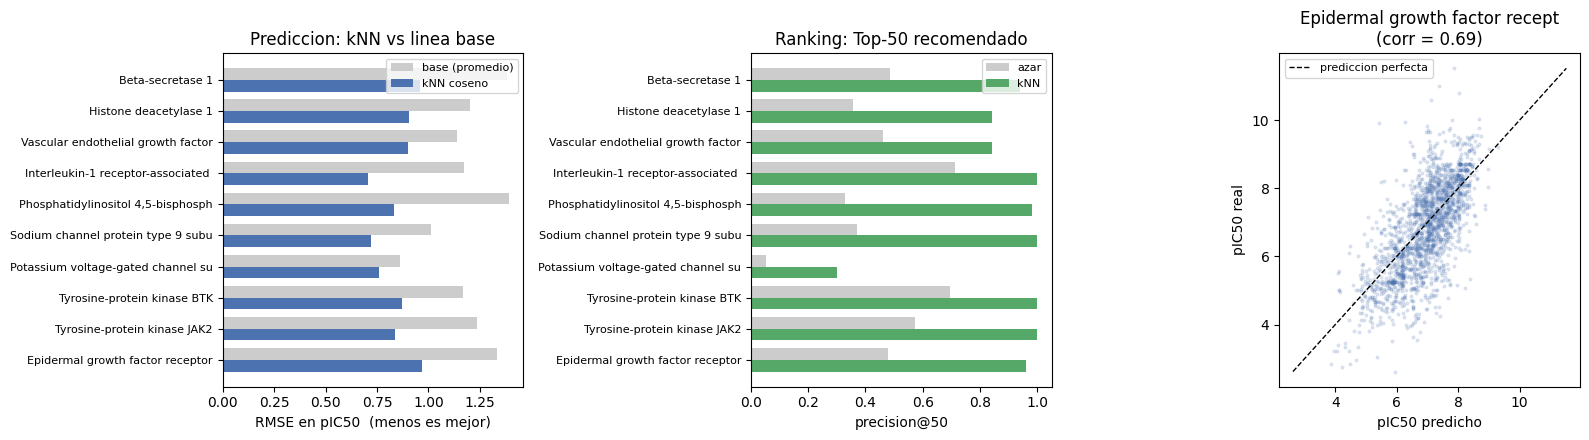

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
y_pos = np.arange(len(res))
h = .38

ax[0].barh(y_pos + h/2, res["rmse_base"], h, label="base (promedio)", color="#CCCCCC")
ax[0].barh(y_pos - h/2, res["rmse_knn"], h, label="kNN coseno", color="#4C72B0")
ax[0].set_yticks(y_pos); ax[0].set_yticklabels(res["proteina"], fontsize=8)
ax[0].set_xlabel("RMSE en pIC50  (menos es mejor)")
ax[0].set_title("Prediccion: kNN vs linea base")
ax[0].legend(fontsize=8)

ax[1].barh(y_pos + h/2, res["%act_test"], h, label="azar", color="#CCCCCC")
ax[1].barh(y_pos - h/2, res["p@50_knn"], h, label="kNN", color="#55A868")
ax[1].set_yticks(y_pos); ax[1].set_yticklabels(res["proteina"], fontsize=8)
ax[1].set_xlabel("precision@50")
ax[1].set_title("Ranking: Top-50 recomendado")
ax[1].legend(fontsize=8)

g = guardado
ax[2].scatter(g["pred_knn"], g["yte"], s=4, alpha=.15, color="#4C72B0")
lim = [min(g["yte"].min(), g["pred_knn"].min()), max(g["yte"].max(), g["pred_knn"].max())]
ax[2].plot(lim, lim, "k--", lw=1, label="prediccion perfecta")
ax[2].set_xlabel("pIC50 predicho"); ax[2].set_ylabel("pIC50 real")
ax[2].set_title(f"{g['nombre'][:30]}\n(corr = {np.corrcoef(g['pred_knn'], g['yte'])[0,1]:.2f})")
ax[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Lo que leemos de esto

**Sí funciona.** El kNN baja el RMSE de **1.19** (predecir el promedio) a **0.85**, ganando en las 10 proteínas, y la precision@50 sube de **45%** (azar) a **89%**. Con el split con fuga salía 0.81 y 94%, así que la fuga nos regalaba poco en general.

**La excepción es hERG.** Con el split aleatorio su precision@50 era 64%; con el honesto baja a **30%** (contra 5% de azar). Era la proteína con menos activos y la que más dependía de las gemelas. Ahí Naive Bayes (40%) le gana al kNN.

**Otras observaciones:**

- Un RMSE de 0.85 equivale a un factor de ~7 en IC50. Hay margen, y lo atribuimos sobre todo a que los n-gramas son un descriptor pobre.
- El kNN **achata** las predicciones: en EGFR los pIC50 reales tienen desviación 1.33 y los predichos 0.90 (correlación 0.69). Se pierden los extremos pero se conserva el orden, que es lo que importa para rankear.
- Ponderar con Dev(w) **empeoró en las 10 proteínas** (0.880 vs 0.846). Probablemente porque la constante `+0.1` la fijamos a ojo y porque subirle peso a fragmentos raros desestabiliza el coseno.
- Naive Bayes queda abajo del kNN (80% vs 89% en p@50, AUC 0.78), pero se entrena una sola vez y predice rápido, lo cual pesaría con el catálogo completo.

## 9. Componente 3: filtrado y recomendación (el Top-k)

Ya con el perfil aprendido, esta es la parte que iría **en línea**. Le llegamos con una proteína y nos regresa su Top-k.

El pool de candidatos es la parte bonita del asunto: usamos moléculas que **sí fueron medidas, pero contra otras proteínas**. O sea moléculas que existen y que alguien ya sintetizó, nomás que a nadie se le ocurrió probarlas contra *ésta*. Son huecos reales de la matriz, no inventados — exactamente el caso de uso del *drug repurposing*.

Además devolvemos la similitud del vecino más cercano junto con la predicción

In [20]:
def recomendar(nombre, k=10, n_candidatos=20_000, semilla=SEMILLA):
    """Top-k de ligandos que esta proteina NO tiene medidos."""
    dt = sub[sub["target"] == nombre]
    ya = set(dt["smiles"])
    y = dt["pic50"].to_numpy()
    Xtr = X[dt["smiles"].map(fila).to_numpy()]

    candidatos = ligandos[~ligandos.isin(ya)]
    if len(candidatos) > n_candidatos:               # muestreamos para que corra rapido
        candidatos = candidatos[np.random.default_rng(semilla)
                                  .choice(len(candidatos), n_candidatos, replace=False)]
    Xc = X[[fila[s] for s in candidatos]]

    pred, sim, vecinos = knn_predice(Xtr, y, Xc)
    mejor = sim.argmax(axis=1)
    out = pd.DataFrame({
        "pIC50_predicho": pred,
        "sim_vecino": sim[np.arange(len(pred)), mejor],
        "porque_se_parece_a": [dt["smiles"].iloc[vecinos[i, mejor[i]]][:44] + "..."
                               for i in range(len(pred))],
        "ese_vecino_dio": y[vecinos[np.arange(len(pred)), mejor]],
        "ligando": [s[:44] + "..." if len(s) > 44 else s for s in candidatos],
    })
    return out.nlargest(k, "pIC50_predicho").reset_index(drop=True)


obj = resumen.index[0]
print(f"TOP 10 recomendados para: {obj}")
print(f"(de {len(ligandos) - resumen.loc[obj, 'mediciones']:,} ligandos que NO tiene medidos)\n")
recomendar(obj, 10).round(2)

TOP 10 recomendados para: Epidermal growth factor receptor
(de 78,879 ligandos que NO tiene medidos)



,pIC50_predicho,sim_vecino,porque_se_parece_a,ese_vecino_dio,ligando
0,9.05,0.39,OCc1ccc(-c2cc3c(N[C@H](CO)c4ccccc4)ncnc3[nH]...,9.70,CC(C)Oc1cc(-n2cnc3ccc(N[C@@H](CO)c4ccc(F)cn4...
1,8.86,0.44,Cc1cc(N2Cc3ccccc3C2)nc2ccc(Cl)cc12...,7.50,CCc1cc(O)ccc1-c1cc2[nH]ncc2c(N2CCc3cc(F)ccc3...
2,8.82,0.33,COc1cc(CN(C)CCN(C)C)ccc1-c1cc2c(N[C@H](CO)c3...,10.00,Cc1ccc2[nH]c(C(=O)N[C@H]3Cc4ccccc4[C@H]3NC(=...
3,8.77,0.32,CCOc1ccccc1-c1cc2c(N[C@H](C)c3ccccc3)ncnc2[n...,9.52,COc1cc2nc(C)ccc2cc1-c1cnc([C@H](CCCCCC(=O)c2...
4,8.74,0.33,COc1cc(CN(C)CCN(C)C)ccc1-c1cc2c(N[C@H](CO)c3...,10.00,Cc1nn(C(C)C)cc1-c1nc2c(-c3ccc4c(c3)CCCC[C@@H...
5,8.68,0.46,COc1cc2nc(Cl)nc(Nc3ccc(cc3)S(=O)(=O)Nc3nccs3...,5.01,COc1cc(C(F)(F)F)ccc1-c1c(C#N)cnc2cc(S(=O)(=O...
6,8.66,0.41,CCOc1cc2ncnc(Nc3cccc(c3)-c3nccs3)c2cc1OCC...,8.70,COC1CCC2(CC1)Cc1ccc(C#CC3CC3)cc1C21N=C(SCc2c...
7,8.64,0.62,C[C@@H](Nc1ncnc2[nH]c(-c3ccc(NS(C)(=O)=O)cc3...,9.52,CN(c1ncnc2[nH]ccc12)[C@H]1C[C@@H](NS(C)(=O)=...
8,8.63,0.45,COc1cc2nc(Cl)nc(Nc3ccc(cc3)S(=O)(=O)Nc3nccs3...,5.01,FC(F)(F)c1cc(-c2ccc(Oc3ccc(cc3C#N)S(=O)(=O)N...
9,8.62,0.44,C[C@@H](Nc1ncnc2[nH]c(-c3ccc(C#N)cc3)cc12)c1...,7.92,CC[C@@H]1CN(C(=O)NC(C)C)C[C@@H]1Nc1c(C#N)cnc...


In [21]:
# otra proteina, para ver que los perfiles de verdad son distintos
obj2 = resumen.index[3]
print(f"TOP 10 recomendados para: {obj2}\n")
recomendar(obj2, 10).round(2)

TOP 10 recomendados para: Potassium voltage-gated channel subfamily H member 2



,pIC50_predicho,sim_vecino,porque_se_parece_a,ese_vecino_dio,ligando
0,7.93,0.50,CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F...,8.47,CCCc1cn(nn1)-c1cnc(cc1Nc1cnn(CC(F)F)c1)-n1nc...
1,7.61,0.49,Cc1nccn1Cc1cn(nn1)-c1ccc(cc1)C(F)(F)F...,7.34,CC(C)(O)CCc1cn(nn1)-c1cnc(cc1NCCC(F)(F)F)-n1...
2,7.58,0.50,Cn1nccc1Cc1cn(nn1)-c1ccc(F)c(Cl)c1...,5.36,CC(C)Nc1cc(ncc1-c1cn(nn1)-c1ccc(F)cc1)-n1ncc...
3,7.56,0.53,CCCc1nccn1Cc1cn(nn1)-c1ccc(F)c(c1)C(F)F...,8.47,CCCc1cc(nn1Cc1ccc(cc1)C(=O)NO)-c1ccc(F)cc1
4,7.53,0.42,Cc1ccc(CN2[C@@H]3CC[C@H]2C[C@@H](Oc2cccc(C(N...,6.59,Cc1cc(Oc2ccccc2)ccc1N1C(=O)Nc2c(C(=O)N[C@H]3...
5,7.50,0.54,Nc1c(nnn1Cc1ccc(CN2CCOCC2)cc1)C(=O)Nc1cccc(F...,5.15,Cc1cc(nn1Cc1ccc(cc1)C(=O)NO)-c1ccc(F)cc1
6,7.48,0.41,Cc1ccc(CN2[C@@H]3CC[C@H]2C[C@@H](Oc2cccc(C(N...,6.59,Cc1cc(Oc2ccccc2)ccc1N1C(=O)Nc2c(C(=O)N[C@H]3...
7,7.31,0.48,Cc1nccn1Cc1cn(nn1)-c1ccc(cc1)C(F)(F)F...,7.34,O=C1Nc2ccccc2C1=Cc1ccc(cc1)-c1cn(nn1)-c1ccc(...
8,7.29,0.48,Cc1nccn1Cc1cn(nn1)-c1cccc(c1)C1CC1...,7.80,CC(F)Cc1cn(nn1)-c1cnc(cc1NC1CC1)-n1ncc2cc(cn...
9,7.24,0.52,NC(=O)c1cccc(O[C@@H]2C[C@H]3CC[C@@H](C2)N3C2...,7.82,CNS(=O)(=O)NC(=O)c1cc(Cl)c(O[C@@H]2C[C@@H]3C...


Lo que vemos en estos Top-10:

1. **Cada proteína tiene su propio perfil.** Para EGFR salen bicíclicos nitrogenados tipo aminopirimidina (la familia de sus inhibidores reales); para el canal de potasio, triazoles con flúor.
2. **Cada recomendación trae su porqué** (el vecino que la detonó y su pIC50), pero es una explicación incompleta: hay casos con vecino de pIC50 5.0 y predicción de 8.7, porque se promedian 25 vecinos.
3. **Arriba del ranking el modelo extrapola más.** Las similitudes del Top-10 (0.3–0.6) están por debajo del promedio de evaluación (~0.60), justo donde menos confiable es.

Además, una molécula recién sintetizada sí se puede rankear porque conocemos su estructura; un filtrado colaborativo no tendría con qué.

### Lo que nos falta: diversidad

Nuestro Top-10 sólo optimiza relevancia, y se nota: varias recomendaciones salen detonadas por la **misma** molécula vecina (en hERG, los renglones 0 y 3, 4 y 6, 1 y 7). Para descubrimiento de fármacos eso es riesgoso, porque 10 análogos de una estructura son 10 experimentos apostados a una sola idea.

Un arreglo simple (no alcanzamos a hacerlo): rankear por relevancia y bajar la lista saltándose cualquier candidato con similitud > 0.8 contra uno ya elegido (*maximal marginal relevance*).

## 10. Conclusiones

**Resultados.** Con el split sin fuga, el kNN baja el RMSE de **1.19** (predecir el promedio) a **0.85** y gana en las 10 proteínas. En ranking, la precision@50 sube de **45%** (azar) a **89%**. Naive Bayes queda abajo (80%, AUC 0.78), aunque le gana al kNN en hERG. Ponderar features con Dev(w) empeoró en las 10 proteínas.



**Limitaciones.**

- Los n-gramas de caracteres son un descriptor débil; lo primero sería cambiarlos por fingerprints ECFP de RDKit.
- Queda ~0.1% de fuga residual (límite de 20 vecinas en el grafo).
- Tiramos los datos censurados (`>`, `<`, el 22%), y el catálogo ya está sesgado hacia moléculas buenas.
- El Top-k sólo optimiza relevancia: recomienda casi duplicados, y no distingue targets de antitargets como hERG.

